In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")


In [ ]:
df = pd.read_csv("/content/food_delivery_orders_dataset.csv")

In [ ]:
df.head()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,Medium,14,4.4,25,25,29.0,0.0,Completed,NaN,4.6
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,High,44,4.7,12,20,24.0,0.0,Completed,NaN,5.0
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,High,1,5.0,11,63,72.0,1.0,Completed,NaN,3.6
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,Low,50,4.3,12,23,31.0,1.0,Completed,NaN,4.1
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,Medium,21,4.0,9,32,42.0,1.0,Completed,NaN,3.9


In [ ]:
df.tail()

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
49995,ORD_049996,CUS_00280,RES_0130,DRV_0112,2025-10-25 12:16:00,2025-10-25,12,Saturday,1,City_B,...,Medium,34,5.0,11,19,21.0,0.0,Completed,NaN,4.4
49996,ORD_049997,CUS_00893,RES_0028,DRV_0036,2025-10-05 19:48:00,2025-10-05,19,Sunday,1,City_B,...,High,49,5.0,9,28,29.0,0.0,Completed,NaN,4.8
49997,ORD_049998,CUS_01618,RES_0001,DRV_0071,2025-10-08 12:18:00,2025-10-08,12,Wednesday,0,City_A,...,High,54,4.1,11,18,16.0,0.0,Completed,NaN,4.7
49998,ORD_049999,CUS_00025,RES_0057,DRV_0103,2025-10-20 17:39:00,2025-10-20,17,Monday,0,City_A,...,High,33,4.0,20,17,27.0,1.0,Completed,NaN,3.8
49999,ORD_050000,CUS_00038,RES_0139,DRV_0131,2025-10-13 17:36:00,2025-10-13,17,Monday,0,City_A,...,Low,44,4.7,12,30,40.0,1.0,Completed,NaN,4.5


In [ ]:
df.shape

(50000, 37)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   order_id                             50000 non-null  object 
 1   customer_id                          50000 non-null  object 
 2   restaurant_id                        50000 non-null  object 
 3   driver_id                            50000 non-null  object 
 4   order_timestamp                      50000 non-null  object 
 5   order_date                           50000 non-null  object 
 6   order_hour                           50000 non-null  int64  
 7   day_of_week                          50000 non-null  object 
 8   is_weekend                           50000 non-null  int64  
 9   city                                 50000 non-null  object 
 10  delivery_area                        50000 non-null  object 
 11  customer_age                

In [ ]:
df.columns

Index(['order_id', 'customer_id', 'restaurant_id', 'driver_id',
       'order_timestamp', 'order_date', 'order_hour', 'day_of_week',
       'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type',
       'restaurant_type', 'restaurant_primary_category', 'restaurant_rating',
       'items_count', 'subtotal', 'discount_percent', 'tax_amount',
       'service_fee', 'delivery_fee', 'order_total', 'payment_method',
       'tip_amount', 'distance_km', 'weather', 'traffic_level',
       'delivery_partner_experience_months', 'delivery_partner_rating',
       'restaurant_preparation_time_minutes',
       'estimated_delivery_time_minutes', 'actual_delivery_time_minutes',
       'late_delivery', 'order_status', 'cancellation_reason',
       'customer_rating'],
      dtype='object')

In [ ]:
df.describe()

,order_hour,is_weekend,customer_age,restaurant_rating,items_count,subtotal,discount_percent,tax_amount,service_fee,delivery_fee,order_total,tip_amount,distance_km,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,customer_rating
count,50000.000000,50000.00000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,49132.000000,50000.000000,50000.0000,50000.000000,50000.000000,50000.000000,49132.000000,49132.000000,49132.000000
mean,14.465900,0.26712,27.686580,4.207956,2.91002,30.897938,4.495700,4.128796,1.474600,3.075108,38.169501,1.610076,4.730632,29.7332,4.495062,15.549600,30.950580,35.152365,0.365709,4.295946
std,5.231155,0.44246,7.537796,0.450977,2.02907,27.068965,6.430008,3.636275,1.378101,2.299115,31.054669,2.878464,2.780190,17.4052,0.349198,7.360099,12.825519,14.701154,0.481633,0.530947
min,0.000000,0.00000,18.000000,2.800000,1.00000,5.100000,0.000000,0.570000,0.130000,0.000000,4.870000,0.000000,0.800000,1.0000,3.200000,5.000000,8.000000,10.000000,0.000000,1.800000
25%,11.000000,0.00000,21.000000,3.900000,1.00000,13.100000,0.000000,1.730000,0.580000,0.000000,17.430000,0.000000,2.800000,14.0000,4.300000,10.000000,22.000000,25.000000,0.000000,4.000000
50%,14.000000,0.00000,27.000000,4.200000,2.00000,22.825000,0.000000,2.890000,1.040000,3.500000,28.350000,0.000000,4.100000,29.0000,4.500000,14.000000,28.000000,33.000000,0.000000,4.400000
75%,19.000000,1.00000,33.000000,4.600000,4.00000,40.120000,10.000000,5.390000,1.890000,4.500000,48.660000,2.280000,5.900000,44.0000,4.800000,19.000000,37.000000,42.000000,1.000000,4.700000
max,23.000000,1.00000,55.000000,5.000000,10.00000,362.980000,20.000000,50.820000,25.210000,12.000000,443.210000,53.650000,20.000000,60.0000,5.000000,73.000000,128.000000,172.000000,1.000000,5.000000


In [ ]:
df.describe(include="all")

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating
count,50000,50000,50000,50000,50000,50000,50000.000000,50000,50000.00000,50000,...,50000,50000.0000,50000.000000,50000.000000,50000.000000,49132.000000,49132.000000,50000,868,49132.000000
unique,50000,4979,250,200,25459,30,NaN,7,NaN,4,...,3,NaN,NaN,NaN,NaN,NaN,NaN,2,5,NaN
top,ORD_049984,CUS_00001,RES_0001,DRV_0066,2025-10-11 19:51:00,2025-10-23,NaN,Thursday,NaN,City_A,...,Medium,NaN,NaN,NaN,NaN,NaN,NaN,Completed,Driver Unassigned,NaN
freq,1,4510,8837,315,9,1741,NaN,8472,NaN,19888,...,19522,NaN,NaN,NaN,NaN,NaN,NaN,49132,386,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,14.465900,NaN,0.26712,NaN,...,NaN,29.7332,4.495062,15.549600,30.950580,35.152365,0.365709,NaN,NaN,4.295946
std,NaN,NaN,NaN,NaN,NaN,NaN,5.231155,NaN,0.44246,NaN,...,NaN,17.4052,0.349198,7.360099,12.825519,14.701154,0.481633,NaN,NaN,0.530947
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.00000,NaN,...,NaN,1.0000,3.200000,5.000000,8.000000,10.000000,0.000000,NaN,NaN,1.800000
25%,NaN,NaN,NaN,NaN,NaN,NaN,11.000000,NaN,0.00000,NaN,...,NaN,14.0000,4.300000,10.000000,22.000000,25.000000,0.000000,NaN,NaN,4.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,14.000000,NaN,0.00000,NaN,...,NaN,29.0000,4.500000,14.000000,28.000000,33.000000,0.000000,NaN,NaN,4.400000
75%,NaN,NaN,NaN,NaN,NaN,NaN,19.000000,NaN,1.00000,NaN,...,NaN,44.0000,4.800000,19.000000,37.000000,42.000000,1.000000,NaN,NaN,4.700000


In [ ]:
df.nunique()

,0
order_id,50000
customer_id,4979
restaurant_id,250
driver_id,200
order_timestamp,25459
order_date,30
order_hour,24
day_of_week,7
is_weekend,2
city,4


**checking unique values in important categorical columns**

In [ ]:
df["customer_type"].value_counts()

,count
customer_type,
Regular,25098
Premium,14727
New,10175


In [ ]:
df["restaurant_primary_category"].value_counts()

,count
restaurant_primary_category,
Burger,16184
Local,12747
Dessert,9587
Pizza,4095
Asian,3799
Healthy,3588


In [ ]:
df["traffic_level"].value_counts()

,count
traffic_level,
Medium,19522
High,15313
Low,15165


In [ ]:
df["weather"].value_counts()

,count
weather,
Clear,28248
Cloudy,12810
Rain,7627
Storm,1315


In [ ]:
df["order_status"].value_counts()

,count
order_status,
Completed,49132
Cancelled,868


**check number of unique entities**

In [ ]:
df["order_id"].nunique()

50000

In [ ]:
df['customer_id'].nunique()

4979

In [ ]:
df["restaurant_id"].nunique()

250

In [ ]:
df["driver_id"].nunique()

200

**Missing value & Duplicate Analysis**

In [ ]:
df.isnull().sum()

,0
order_id,0
customer_id,0
restaurant_id,0
driver_id,0
order_timestamp,0
order_date,0
order_hour,0
day_of_week,0
is_weekend,0
city,0


In [ ]:
missing = df.isnull().sum()
missing_percentage = (missing / len(df)) *100
missing_percentage

,0
order_id,0.000
customer_id,0.000
restaurant_id,0.000
driver_id,0.000
order_timestamp,0.000
order_date,0.000
order_hour,0.000
day_of_week,0.000
is_weekend,0.000
city,0.000


In [ ]:
missing_table = pd.DataFrame({
    "Missing_values" : missing,
    "Missing _Percentage" : missing_percentage
}).sort_values("Missing_values",ascending=False)

missing_table

,Missing_values,Missing _Percentage
cancellation_reason,49132,98.264
actual_delivery_time_minutes,868,1.736
tip_amount,868,1.736
late_delivery,868,1.736
customer_rating,868,1.736
order_timestamp,0,0.000
driver_id,0,0.000
restaurant_id,0,0.000
customer_id,0,0.000
order_id,0,0.000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["order_id"].duplicated().sum()

np.int64(0)

In [ ]:
df["order_id"].nunique()


50000

In [ ]:
print(len(df))

50000


#**Data type Validation**

In [ ]:
df.dtypes

,0
order_id,object
customer_id,object
restaurant_id,object
driver_id,object
order_timestamp,object
order_date,object
order_hour,int64
day_of_week,object
is_weekend,int64
city,object


In [ ]:
df["order_timestamp"] =pd.to_datetime(
    df["order_timestamp"],
    errors="coerce"
)

In [ ]:
df["order_date"] = pd.to_datetime(
    df['order_date'],
    errors="coerce"
)

In [ ]:
#checking if it converted to datetime data types

df[["order_timestamp","order_date"]].dtypes

,0
order_timestamp,datetime64[ns]
order_date,datetime64[ns]


In [ ]:
#date range
df["order_date"].min()


Timestamp('2025-10-01 00:00:00')

In [ ]:
df["order_date"].max()

Timestamp('2025-10-30 00:00:00')

In [ ]:
#validate customer age
df["customer_age"].describe()

,customer_age
count,50000.000000
mean,27.686580
std,7.537796
min,18.000000
25%,21.000000
50%,27.000000
75%,33.000000
max,55.000000


In [ ]:
df[
    (df["customer_age"]<18) |
    (df["customer_age"]>100)
]

,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,traffic_level,delivery_partner_experience_months,delivery_partner_rating,restaurant_preparation_time_minutes,estimated_delivery_time_minutes,actual_delivery_time_minutes,late_delivery,order_status,cancellation_reason,customer_rating


In [ ]:
#validate resturant rating
((df["restaurant_rating"] < 1) |
 (df["restaurant_rating"] > 5)).sum()

np.int64(0)

In [ ]:
#validate delivery partner rating
((df["delivery_partner_rating"] < 1) |
 (df["delivery_partner_rating"] > 5)).sum()

np.int64(0)

In [ ]:
#validate customer rating
((df["customer_rating"].dropna() < 1) |
(df["customer_rating"].dropna() > 5)).sum()

np.int64(0)

In [ ]:
#check negative financial values
financial_columns = [
    "subtotal",
    "tax_amount",
    "service_fee",
    "delivery_fee",
    "order_total"
]

In [ ]:
for column in financial_columns:
  print(column, (df[column]<0).sum())

subtotal 0
tax_amount 0
service_fee 0
delivery_fee 0
order_total 0


In [ ]:
#validate discount percentage
df["discount_percent"].describe()

,discount_percent
count,50000.000000
mean,4.495700
std,6.430008
min,0.000000
25%,0.000000
50%,0.000000
75%,10.000000
max,20.000000


In [ ]:
((df["discount_percent"] < 0) |
 (df["discount_percent"] > 100)).sum()

np.int64(0)

In [ ]:
#validate distance
(df["distance_km"] < 0 ).sum()

np.int64(0)

In [ ]:
#validate delivery times
(df["estimated_delivery_time_minutes"] <= 0).sum()

np.int64(0)

In [ ]:
(df["actual_delivery_time_minutes"].dropna() <= 0 ).sum()

np.int64(0)

In [ ]:
#Financial validation
df["calculated_order_total"] = (
    df["subtotal"] * (1 - df["discount_percent"] / 100)
    + df["tax_amount"]
    + df["service_fee"]
    + df["delivery_fee"]
)

In [ ]:
df["total_difference"] = (
    df["order_total"] - df["calculated_order_total"]
)


In [ ]:
df["total_difference"].abs().max()

0.005000000000052296

In [ ]:
#creating discount amount
df["discount_amount"] = (
    df["subtotal"] - df["discount_percent"] / 100
 )

**check order status**

In [ ]:

df["order_status"].value_counts()

,count
order_status,
Completed,49132
Cancelled,868


In [ ]:
# Investigating missing delivery times by order status
pd.crosstab(
    df["order_status"],
    df["actual_delivery_time_minutes"].isnull()
)

actual_delivery_time_minutes,False,True
order_status,,
Cancelled,0,868
Completed,49132,0


In [ ]:
#check existing 'late delivery' field
df["calculated_delay"] = (
    df["actual_delivery_time_minutes"]
    > df["estimated_delivery_time_minutes"]
)

In [ ]:
completed_check = df[df["order_status"] == "Completed"].copy()

In [ ]:
#Now compare this with the existing 'late_delivery' field for completed orders
pd.crosstab(
    completed_check["late_delivery"],
    completed_check["calculated_delay"]
)

calculated_delay,False,True
late_delivery,,
0.0,11833,19331
1.0,0,17968


### Observation

- All 868 cancelled orders have missing actual delivery times, which is
  logically valid because these orders were not completed.
- All 49,132 completed orders contain actual delivery times.
- Therefore, missing actual delivery times should not be imputed and
  completed orders should be used for delivery-time analysis.
- Comparison of the existing `late_delivery' field with a delay calculated
  as Actual Delivery Time > Estimated Delivery Time revealed inconsistencies.
- 19,331 completed orders exceeded their estimated delivery time but were
  marked as `late_delivery = 0'.
- Therefore, the original `late_delivery' field will be preserved, while a
  separate derived delay measure will be created for ETA and delay analysis.

In [ ]:
#remove temporary validation columns
df.drop(
    columns=["calculated_order_total","total_difference"],
    inplace=True
)

In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
cancellation_reason,49132
customer_rating,868
tip_amount,868
actual_delivery_time_minutes,868
late_delivery,868
customer_id,0
order_id,0
order_hour,0
order_date,0
order_timestamp,0


In [ ]:
#actual_delivery_time_minutes → missing for cancelled orders
#customer_rating             → may be missing for cancelled orders
#late_delivery               → may be missing for cancelled orders
#tip_amount                  → may be missing for cancelled orders
#cancellation_reason         → missing for completed orders

#Missing values associated with cancelled orders were retained because they represent logically unavailable information rather than data errors.
#Therefore it cannot be replaced using mean,median,mode or other techniques

In [ ]:
df.drop(columns=["calculated_delay"],inplace=True) #removing because creating better variables

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Standardize text values (accidental spaces)
# Categorical columns to standardize
categorical_columns = [
    "customer_type",
    "restaurant_primary_category",
    "traffic_level",
    "weather",
    "order_status"
]

for column in categorical_columns:
    df[column] = df[column].str.strip()


In [ ]:
for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 customer_type
customer_type
Regular    25098
Premium    14727
New        10175
Name: count, dtype: int64

 restaurant_primary_category
restaurant_primary_category
Burger     16184
Local      12747
Dessert     9587
Pizza       4095
Asian       3799
Healthy     3588
Name: count, dtype: int64

 traffic_level
traffic_level
Medium    19522
High      15313
Low       15165
Name: count, dtype: int64

 weather
weather
Clear     28248
Cloudy    12810
Rain       7627
Storm      1315
Name: count, dtype: int64

 order_status
order_status
Completed    49132
Cancelled      868
Name: count, dtype: int64


In [ ]:
#creating completed orders dataset
completed = df[df["order_status"] == "Completed"].copy()

In [ ]:
completed.shape #completed orders

(49132, 38)

In [ ]:
df.shape #all 50000 orders

(50000, 38)

### Data Cleaning Summary

- No complete duplicate records were identified.
- Order IDs were checked for uniqueness.
- Date columns were converted to appropriate datetime formats.
- Missing delivery-related values for cancelled orders were retained because
  they represent logically unavailable information.
- Categorical text columns were standardized by removing unnecessary spaces.
- The original `late_delivery` field was preserved because its business rule
  is unknown.
- A separate completed-orders dataset was created for delivery-time analysis.
- No unnecessary mean/median imputation was performed.

#**Feature Engineering**

In [ ]:
#create delay minutes
df["delay_minutes"] = (
    df["actual_delivery_time_minutes"]
    - df["estimated_delivery_time_minutes"]
)
#delay_minutes > 0  → exceeded ETA
#delay_minutes = 0  → exactly on ETA
#delay_minutes < 0  → earlier than ETA

In [ ]:
#create derived delay indicator
df["is_delayed"] = np.where(
    df["delay_minutes"] > 0,
    1,
    0
)

In [ ]:
#Important correction for cancelled orders
#Right now, cancelled orders have delay_minutes = NaN.
#We don't want Python to classify those as 0, because that would incorrectly mean: Cancelled order was delivered on time.
df.loc[
    df["order_status"] == "Cancelled",
    "is_delayed"
] = np.nan

#Find rows where order_status is Cancelled and set their is_delayed value to missing.
#That's the correct interpretation because we cannot determine delivery delay for an order that wasn't delivered.

In [ ]:
#update 'completed' dataset
completed = df[df["order_status"] == "Completed"].copy()

In [ ]:
#verify delay feature
completed["is_delayed"].value_counts()
#0 → did not exceed ETA
#1 → exceeded ETA

,count
is_delayed,
1.0,37299
0.0,11833


In [ ]:
completed["is_delayed"].value_counts(normalize=True) * 100

,proportion
is_delayed,
1.0,75.9159
0.0,24.0841


In [ ]:
#Create customer age groups
df["age_group"] = pd.cut(
    df["customer_age"],
    bins=[17, 24, 34, 44, 54, 64, np.inf],
    labels=[
        "18-24",
        "25-34",
        "35-44",
        "45-54",
        "55-64",
        "65+"
    ]
)

In [ ]:
df["age_group"].value_counts().sort_index()

,count
age_group,
18-24,17465
25-34,21895
35-44,9774
45-54,859
55-64,7
65+,0


In [ ]:
#create Day type
df["day_type"] = np.where(
    df["is_weekend"] == 1,
    "Weekend",
    "Weekday"
)
#is_weekend = 1 → Weekend
#is_weekend = 0 → Weekday

In [ ]:
#create time of day
def get_time_of_day(hour):
  if 6<= hour < 12:
    return "Morning"
  elif 12<= hour <17:
    return "Afternoon"
  elif 17 <= hour < 22:
    return "Evening"
  else:
      return "Night"


In [ ]:
df["time_of_day"] =df["order_hour"].apply(get_time_of_day)

In [ ]:
df["time_of_day"].value_counts()

,count
time_of_day,
Evening,18370
Afternoon,14477
Morning,12009
Night,5144


In [ ]:
#create distance categories
df["distance_category"] = pd.cut(
    df["distance_km"],
    bins=[0,3,6,10,np.inf],
    labels=[
        "Short",
        "Medium",
        "Long",
        "Very Long"
    ]
)
#0–3 km   → Short
#3–6 km   → Medium
#6–10 km  → Long
#10+ km   → Very Long

In [ ]:
df["distance_category"].value_counts().sort_index()

,count
distance_category,
Short,15093
Medium,23154
Long,9192
Very Long,2561


In [ ]:
#create driver experience groups
df["driver_experience_group"] = pd.cut(
    df["delivery_partner_experience_months"],
    bins=[-1, 6, 12, 24, np.inf],
    labels=[
        "0-6 Months",
        "7-12 Months",
        "13-24 Months",
        "25+ Months"
    ]
)

In [ ]:
df["driver_experience_group"].value_counts().sort_index()

,count
driver_experience_group,
0-6 Months,5925
7-12 Months,5188
13-24 Months,10466
25+ Months,28421


In [ ]:
#create discount groups
df["discount_group"] = pd.cut(
    df["discount_percent"],
    bins=[-0.01, 5, 10, 20, 30, np.inf],
    labels=[
        "0-5%",
        "5-10%",
        "10-20%",
        "20-30%",
        "30%+"
    ]
)

In [ ]:
df["discount_group"].value_counts().sort_index()

,count
discount_group,
0-5%,36028
5-10%,5921
10-20%,8051
20-30%,0
30%+,0


In [ ]:
df["discount_amount"].head()

,discount_amount
0,64.82
1,13.03
2,10.02
3,8.76
4,14.88


In [ ]:
df["discount_amount"] = (
    df["subtotal"] *
    df["discount_percent"] / 100
)

In [ ]:
completed = df[df["order_status"] == "Completed"].copy()

In [ ]:
#check new features
df[[
    "customer_age",
    "age_group",
    "order_hour",
    "time_of_day",
    "distance_km",
    "distance_category",
    "delivery_partner_experience_months",
    "driver_experience_group",
    "discount_percent",
    "discount_group",
    "estimated_delivery_time_minutes",
    "actual_delivery_time_minutes",
    "delay_minutes",
    "is_delayed"
]].head(10)

,customer_age,age_group,order_hour,time_of_day,distance_km,distance_category,delivery_partner_experience_months,driver_experience_group,discount_percent,discount_group,estimated_delivery_time_minutes,actual_delivery_time_minutes,delay_minutes,is_delayed
0,40,35-44,15,Afternoon,1.1,Short,14,13-24 Months,0,0-5%,25,29.0,4.0,1.0
1,19,18-24,20,Evening,2.5,Short,44,25+ Months,0,0-5%,20,24.0,4.0,1.0
2,26,25-34,18,Evening,11.8,Very Long,1,0-6 Months,10,5-10%,63,72.0,9.0,1.0
3,18,18-24,16,Afternoon,5.4,Medium,50,25+ Months,10,5-10%,23,31.0,8.0,1.0
4,20,18-24,18,Evening,6.1,Long,21,13-24 Months,20,10-20%,32,42.0,10.0,1.0
5,45,45-54,14,Afternoon,6.7,Long,34,25+ Months,0,0-5%,32,39.0,7.0,1.0
6,25,25-34,19,Evening,5.3,Medium,43,25+ Months,0,0-5%,27,31.0,4.0,1.0
7,25,25-34,7,Morning,3.4,Medium,53,25+ Months,0,0-5%,20,22.0,2.0,1.0
8,28,25-34,14,Afternoon,6.2,Long,46,25+ Months,0,0-5%,37,40.0,3.0,1.0
9,28,25-34,20,Evening,2.0,Short,47,25+ Months,0,0-5%,25,22.0,-3.0,0.0


### Feature Engineering Summary

New analytical features were created from existing variables:

- `delay_minutes` measures the difference between actual and estimated
  delivery time.
- `is_delayed` identifies completed orders that exceeded their ETA.
- `age_group` segments customers by age.
- `day_type` separates weekday and weekend orders.
- `time_of_day` groups orders into morning, afternoon, evening and night.
- `distance_category` groups deliveries based on distance.
- `driver_experience_group` segments delivery partners by experience.
- `discount_group` categorizes orders based on discount percentage.
- `discount_amount` represents the monetary value of discounts.

These features will support in customer, driver, financial, logistics and ETA
analysis

#**General Analysis**

In [ ]:
#What is the total number of orders?
total_orders = df["order_id"].nunique()

print("Total Orders:", total_orders)

Total Orders: 50000


In [ ]:
#How many unique customers?
unique_customers = df["customer_id"].nunique()

print("Unique Customers:", unique_customers)

Unique Customers: 4979


In [ ]:
#How many unique restaurants?
unique_restaurants = df["restaurant_id"].nunique()

print("Unique Restaurants:", unique_restaurants)

Unique Restaurants: 250


In [ ]:
#How any unique drivers?
unique_drivers = df["driver_id"].nunique()

print("Unique Drivers:", unique_drivers)

Unique Drivers: 200


In [ ]:
#What is the Total Order Value?
total_order_value = df["order_total"].sum()

print("Total Order Value:", round(total_order_value, 2))

Total Order Value: 1908475.05


In [ ]:
#What is the Average Order Value?
average_order_value = df["order_total"].mean()

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 38.17


In [ ]:
#What is the Average Delivery Time?
# using 'completed' instead of 'df' because cancelled orders were not delivered.
average_delivery_time = (
    completed["actual_delivery_time_minutes"].mean()
)
print(
    "Average Delivery Time:",
    round(average_delivery_time, 2),
    "minutes"
)

Average Delivery Time: 35.15 minutes


In [ ]:
#What is the Overall Delivery Performance?
#We can evaluate delivery performance using several KPIs:
# average ETA
# average actual delivery time
# average delay
# orders exceeding ETA
# percentage exceeding ETA

In [ ]:
average_eta = (completed["estimated_delivery_time_minutes"].mean())
print("Average ETA:", round(average_eta, 2), "minutes")

Average ETA: 30.92 minutes


In [ ]:
average_delay = completed["delay_minutes"].mean()
print("Average Delay:",round(average_delay, 2),"minutes")

Average Delay: 4.23 minutes


In [ ]:
delayed_orders = int(completed["is_delayed"].sum())
print("Orders Exceeding ETA:", delayed_orders)

Orders Exceeding ETA: 37299


In [ ]:
delay_rate = completed["is_delayed"].mean() * 100
print("Orders Exceeding ETA (%):",round(delay_rate, 2),"%")

Orders Exceeding ETA (%): 75.92 %


In [ ]:
#create delivery performance table
delivery_performance = pd.DataFrame({
    "Metric": [
        "Average ETA (Minutes)",
        "Average Delivery Time (Minutes)",
        "Average Delay (Minutes)",
        "Orders Exceeding ETA",
        "Orders Exceeding ETA (%)"
    ],
    "Value": [
        round(average_eta, 2),
        round(average_delivery_time, 2),
        round(average_delay, 2),
        delayed_orders,
        round(delay_rate, 2)
    ]
})

delivery_performance

,Metric,Value
0,Average ETA (Minutes),30.92
1,Average Delivery Time (Minutes),35.15
2,Average Delay (Minutes),4.23
3,Orders Exceeding ETA,37299.00
4,Orders Exceeding ETA (%),75.92


In [ ]:
#create Genreal KPI Summary
general_kpi = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Unique Customers",
        "Unique Restaurants",
        "Unique Drivers",
        "Total Order Value",
        "Average Order Value",
        "Average Delivery Time (Minutes)",
        "Average ETA (Minutes)",
        "Average Delay (Minutes)",
        "Orders Exceeding ETA (%)"
    ],
    "Value": [
        total_orders,
        unique_customers,
        unique_restaurants,
        unique_drivers,
        round(total_order_value, 2),
        round(average_order_value, 2),
        round(average_delivery_time, 2),
        round(average_eta, 2),
        round(average_delay, 2),
        round(delay_rate, 2)
    ]
})

general_kpi

,Metric,Value
0,Total Orders,50000.00
1,Unique Customers,4979.00
2,Unique Restaurants,250.00
3,Unique Drivers,200.00
4,Total Order Value,1908475.05
5,Average Order Value,38.17
6,Average Delivery Time (Minutes),35.15
7,Average ETA (Minutes),30.92
8,Average Delay (Minutes),4.23
9,Orders Exceeding ETA (%),75.92


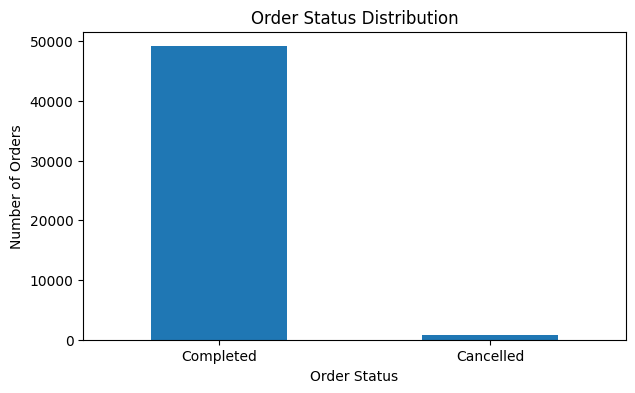

In [ ]:
#visualization
order_status_counts = df["order_status"].value_counts()
order_status_counts.plot(kind="bar",figsize=(7, 4))
plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.show()

#**Customer Analysis**

In [ ]:
#We will be using 'df' dataset instead of 'completed' dataset because we are understanding customer order behaviour not delivery analysis.
#Which customer type generates the most orders?
customer_orders =
(df.groupby("customer_type")["order_id"]
.count()
.sort_values(ascending=False))

customer_orders

,order_id
customer_type,
Regular,25098
Premium,14727
New,10175


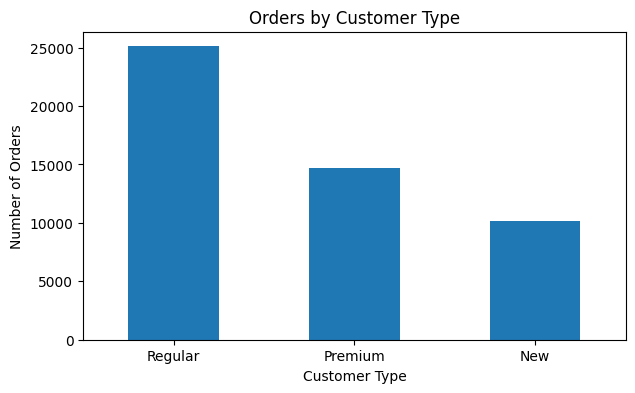

In [ ]:
#visualize
customer_orders.plot(kind="bar",figsize=(7, 4))
plt.title("Orders by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#Which customer type has the Highest Average Order Value?
customer_avg_order = (
df.groupby("customer_type")["order_total"]
.mean()
.sort_values(ascending=False))

customer_avg_order.round(2)

,order_total
customer_type,
New,40.68
Regular,39.62
Premium,33.97


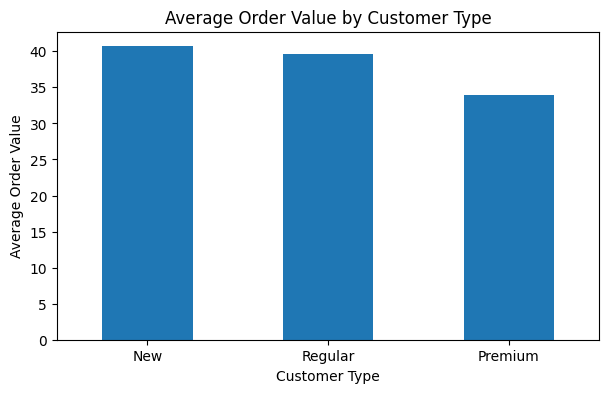

In [ ]:
#visualize
customer_avg_order.plot(kind="bar",figsize=(7, 4))
plt.title("Average Order Value by Customer Type")
plt.xlabel("Customer Type")
plt.ylabel("Average Order Value")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#What is the Customer Age Distribution?
df["customer_age"].describe()

,customer_age
count,50000.000000
mean,27.686580
std,7.537796
min,18.000000
25%,21.000000
50%,27.000000
75%,33.000000
max,55.000000


In [ ]:
#getting unique customers because 'customer_age' technically shows the age distribution across order records, not necessarily a once-per-person demographic distribution.
unique_customers_df = (
    df[["customer_id", "customer_age"]]
    .drop_duplicates(subset="customer_id")
)

In [ ]:
unique_customers_df["customer_age"].describe()

,customer_age
count,4979.000000
mean,27.859410
std,7.233154
min,18.000000
25%,22.000000
50%,27.000000
75%,33.000000
max,55.000000


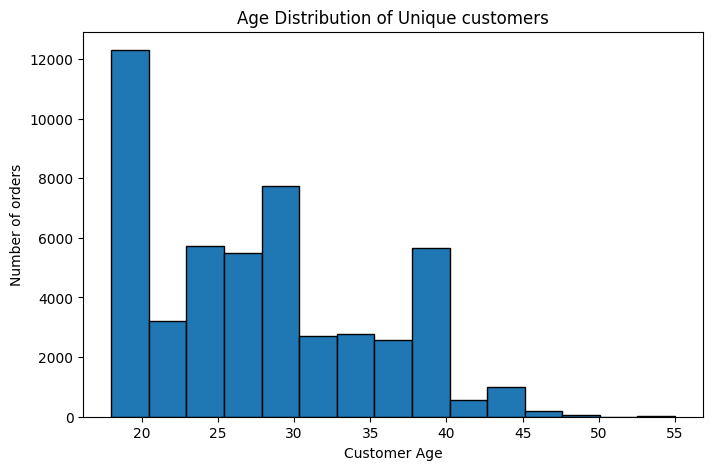

In [ ]:
plt.figure(figsize=(8,5))
plt.hist(df["customer_age"],bins=15,edgecolor="black")
plt.title("Age Distribution of Unique customers")
plt.xlabel("Customer Age")
plt.ylabel("Number of orders")
plt.show()

In [ ]:
#Which age group orders the most?
age_group_orders = (
    df.groupby("age_group",observed=True)["order_id"]
    .count()
    .sort_values(ascending=False)

)

age_group_orders

,order_id
age_group,
25-34,21895
18-24,17465
35-44,9774
45-54,859
55-64,7


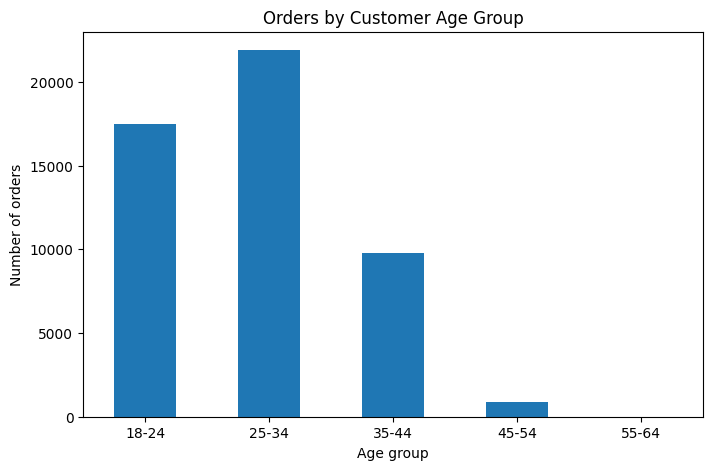

In [ ]:
#visualize
age_group_chart = (
    df.groupby("age_group",observed=True)["order_id"]
    .count()
)

age_group_chart.plot(kind="bar",figsize=(8,5))
plt.title("Orders by Customer Age Group")
plt.xlabel("Age group")
plt.ylabel("Number of orders")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#How does Customer Type affect Order Value?

#creating a customer type analysis
customer_type_analysis = (
    df.groupby("customer_type")
    .agg(
        orders=("order_id","count"),
        avg_order_value=("order_total","mean"),
        total_order_value=("order_total","sum")
    )
    .sort_values("avg_order_value",ascending=False)

)
customer_type_analysis.round(2)

#Average order value differs across customer types, with 40.68 recording the highest average order value.

,orders,avg_order_value,total_order_value
customer_type,,,
New,10175,40.68,413914.03
Regular,25098,39.62,994353.11
Premium,14727,33.97,500207.91


In [ ]:
#Customer Segment Contribution to Total Order Value
customer_contribution= (
    df.groupby("customer_type")["order_total"]
    .sum()
    .sort_values(ascending=False)
)
customer_contribution

,order_total
customer_type,
Regular,994353.11
Premium,500207.91
New,413914.03


In [ ]:
customer_contribution_pct = (
    customer_contribution /
    df["order_total"].sum()
) * 100

customer_contribution_pct.round(2)

,order_total
customer_type,
Regular,52.10
Premium,26.21
New,21.69


In [ ]:
customer_segment_contribution = pd.DataFrame({
    "Total_Order_Value": customer_contribution,
    "Contribution_Percentage": customer_contribution_pct
})

customer_segment_contribution = (
    customer_segment_contribution.round(2)
)

customer_segment_contribution

,Total_Order_Value,Contribution_Percentage
customer_type,,
Regular,994353.11,52.10
Premium,500207.91,26.21
New,413914.03,21.69


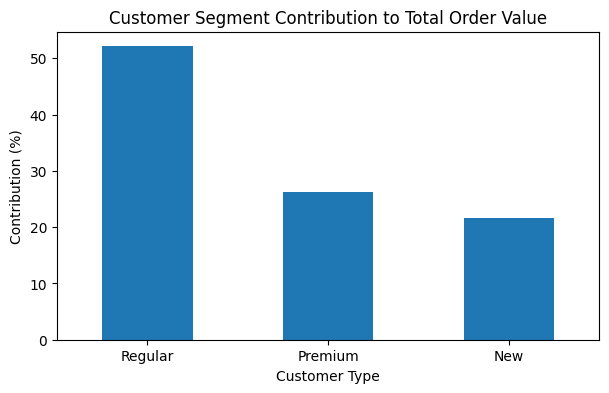

In [ ]:
#visualize
customer_contribution_pct.plot(kind="bar",figsize=(7, 4))
plt.title("Customer Segment Contribution to Total Order Value")
plt.xlabel("Customer Type")
plt.ylabel("Contribution (%)")
plt.xticks(rotation=0)
plt.show()

In [ ]:
#creating customer analysis summary table.
customer_summary = (
    df.groupby("customer_type")
      .agg(
          total_orders=("order_id", "count"),
          unique_customers=("customer_id", "nunique"),
          average_order_value=("order_total", "mean"),
          total_order_value=("order_total", "sum")
      )
)

customer_summary["order_value_contribution_pct"] = (
    customer_summary["total_order_value"]
    / df["order_total"].sum()
) * 100

customer_summary = customer_summary.sort_values("total_orders",ascending=False)

customer_summary.round(2)


,total_orders,unique_customers,average_order_value,total_order_value,order_value_contribution_pct
customer_type,,,,,
Regular,25098,3006,39.62,994353.11,52.10
Premium,14727,992,33.97,500207.91,26.21
New,10175,981,40.68,413914.03,21.69


### Customer Analysis Findings

1. The customer type generating the highest number of orders is "Regular" type.

2. "New" type has the highest average order value at approximately 40.68

3. The customer age distribution shows that most orders are placed by customers aged 18–34, with order frequency decreasing considerably among older age groups.

4. The 25-34 age group places the highest number of orders, with 21,895 orders.

5. Average order value varies across customer types, with 'New' customer showing the highest average spending per order.

6. "Regular" type contributes the largest share of total order value,
   accounting for approximately 52.10% of the total.

#**Restaurant Analysis**

In [ ]:
#for delivery questions we will be using 'completed' dataset otherwise 'df' dataset

#Which Restaurant Category Receives the Most Orders?
category_orders= (
    df.groupby("restaurant_primary_category")["order_id"]
    .count()
    .sort_values(ascending=False)

)
category_orders

,order_id
restaurant_primary_category,
Burger,16184
Local,12747
Dessert,9587
Pizza,4095
Asian,3799
Healthy,3588


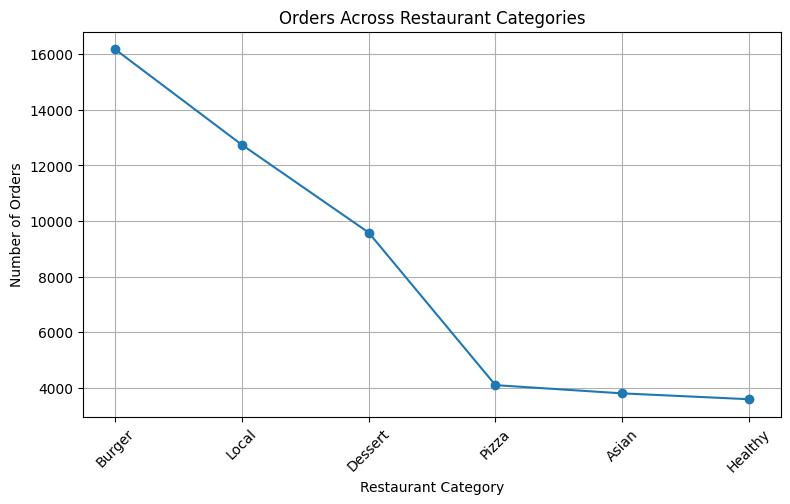

In [ ]:
#visualize
category_orders.head(10).plot(
    kind="line",
    marker="o",
    figsize=(9, 5)
)

plt.title("Orders Across Restaurant Categories")
plt.xlabel("Restaurant Category")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid()

plt.show()

In [ ]:
#Which category generates the Highest Order Value?
category_order_value = (
    df.groupby("restaurant_primary_category")["order_total"]
      .sum()
      .sort_values(ascending=False)
)

category_order_value

,order_total
restaurant_primary_category,
Burger,548857.93
Local,475661.65
Dessert,372612.28
Asian,176333.78
Pizza,168860.51
Healthy,166148.90


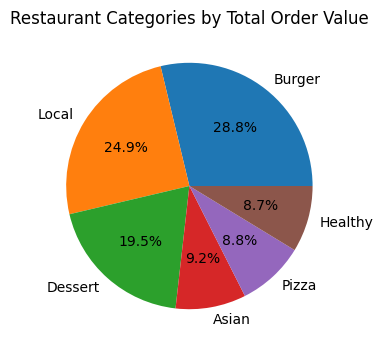

In [ ]:
#visualize
category_order_value.head(10).plot(
    kind="pie",
    figsize=(4, 4),
    autopct="%1.1f%%"
)

plt.title("Restaurant Categories by Total Order Value")
plt.ylabel("")
plt.show()

In [ ]:
#Which restaurants have the Highest Ratings?
restaurant_ratings = (
    df.groupby("restaurant_id")
      .agg(
          avg_rating=("restaurant_rating", "mean"),
          total_orders=("order_id", "count")
      )
      .sort_values(["avg_rating", "total_orders"],
          ascending=[False, False]
      )
)

restaurant_ratings.head(10)

,avg_rating,total_orders
restaurant_id,,
RES_0018,5.0,753
RES_0012,5.0,466
RES_0027,5.0,183
RES_0088,5.0,143
RES_0054,5.0,141
RES_0038,5.0,122
RES_0071,5.0,105
RES_0059,5.0,85
RES_0093,5.0,72


In [ ]:
df.groupby("restaurant_id")["restaurant_rating"].nunique().describe()

,restaurant_rating
count,250.0
mean,1.0
std,0.0
min,1.0
25%,1.0
50%,1.0
75%,1.0
max,1.0


In [ ]:
#Which restaurants have the Longest Preparation Times?
restaurant_prep = ( df.groupby("restaurant_id")
      .agg(
          avg_prep_time=(
              "restaurant_preparation_time_minutes",
              "mean"
          ),
          total_orders=("order_id", "count")
      )
      .sort_values(
          "avg_prep_time",
          ascending=False
      )
)

restaurant_prep.head(10).round(2)

,avg_prep_time,total_orders
restaurant_id,,
RES_0117,32.40,62
RES_0229,32.14,29
RES_0162,31.65,51
RES_0249,31.29,21
RES_0239,30.25,32
RES_0064,30.12,69
RES_0075,29.55,105
RES_0056,29.30,71
RES_0220,28.84,38


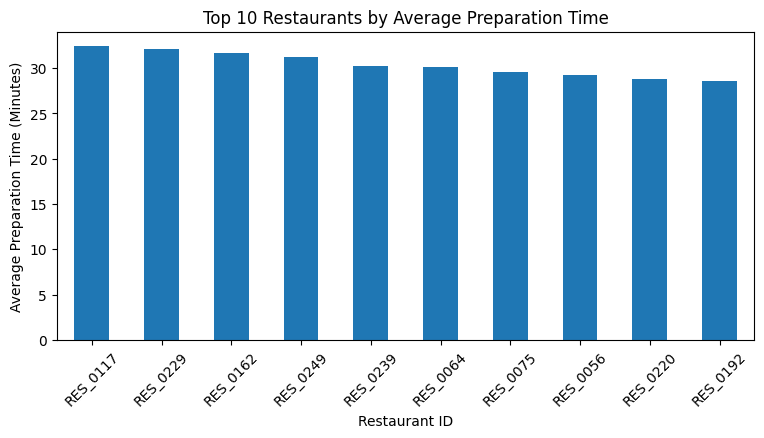

In [ ]:
#visualize
restaurant_prep.head(10)["avg_prep_time"].plot(kind="bar",figsize=(9, 4))
plt.title("Top 10 Restaurants by Average Preparation Time")
plt.xlabel("Restaurant ID")
plt.ylabel("Average Preparation Time (Minutes)")
plt.xticks(rotation=45)
plt.show()

In [ ]:
#How does preparation time affect Delivery Time?
prep_delivery_corr_value = completed[
    "restaurant_preparation_time_minutes"
    ].corr(completed["actual_delivery_time_minutes"])

print(
    "Correlation between preparation time and delivery time:",
    round(prep_delivery_corr_value, 3)
)

Correlation between preparation time and delivery time: 0.501


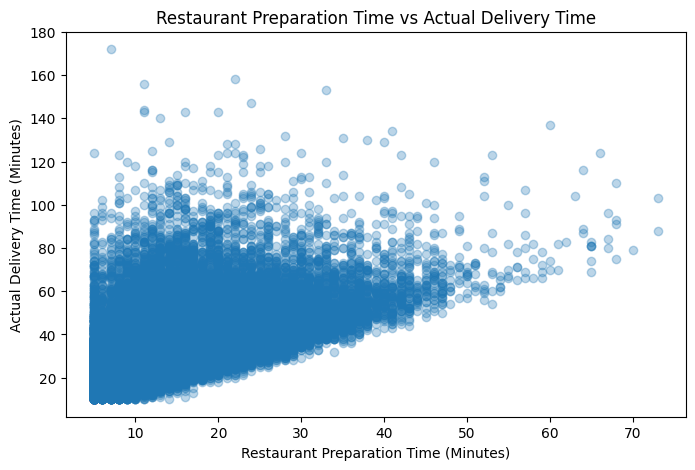

In [ ]:
#visualize
plt.figure(figsize=(8, 5))
plt.scatter(
    completed["restaurant_preparation_time_minutes"],
    completed["actual_delivery_time_minutes"],
    alpha=0.3)
plt.title("Restaurant Preparation Time vs Actual Delivery Time")
plt.xlabel("Restaurant Preparation Time (Minutes)")
plt.ylabel("Actual Delivery Time (Minutes)")
plt.show()

In [ ]:
#grouping preparation times
df["prep_time_group"] = pd.cut(
    df["restaurant_preparation_time_minutes"],
    bins=[0, 10, 20, 30, 40, np.inf],
    labels=[
        "0-10 min",
        "11-20 min",
        "21-30 min",
        "31-40 min",
        "40+ min"
        ]
)

In [ ]:
completed = df[df["order_status"] == "Completed"].copy()

In [ ]:
prep_time_analysis = (
    completed.groupby(
        "prep_time_group",
        observed=True
    )
    .agg(
        orders=("order_id", "count"),
        avg_delivery_time=(
            "actual_delivery_time_minutes",
            "mean"
        ),
        avg_eta=(
            "estimated_delivery_time_minutes",
            "mean"
        ),
        avg_delay=(
            "delay_minutes",
            "mean"
        )
    )
)

prep_time_analysis.round(2)

,orders,avg_delivery_time,avg_eta,avg_delay
prep_time_group,,,,
0-10 min,12434,27.44,26.17,1.27
11-20 min,26466,34.50,29.56,4.94
21-30 min,8220,43.64,37.74,5.90
31-40 min,1611,54.13,47.80,6.32
40+ min,401,67.18,60.73,6.45


In [ ]:
#Which Restaurant Category Has Higher Delivery Times?
category_delivery = (
    completed.groupby("restaurant_primary_category")
      .agg(
          orders=("order_id", "count"),
          avg_delivery_time=(
              "actual_delivery_time_minutes",
              "mean"
          ),
          avg_eta=(
              "estimated_delivery_time_minutes",
              "mean"
          ),
          avg_delay=(
              "delay_minutes",
              "mean"
          )
      )
      .sort_values(
          "avg_delivery_time",
          ascending=False
      )
)

category_delivery.round(2)

,orders,avg_delivery_time,avg_eta,avg_delay
restaurant_primary_category,,,,
Healthy,3541,37.26,33.35,3.91
Asian,3744,36.65,32.39,4.27
Pizza,4026,36.07,31.75,4.32
Dessert,9418,35.47,31.22,4.26
Local,12498,35.04,30.65,4.39
Burger,15905,34.00,29.86,4.14


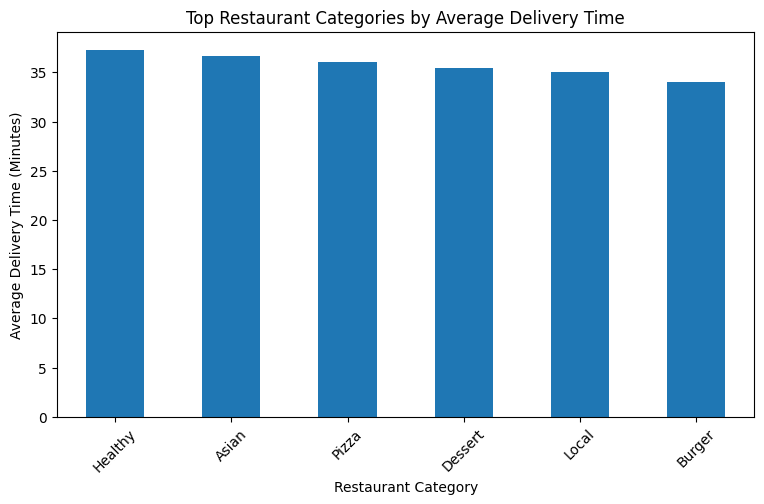

In [ ]:
#visualize
category_delivery.head(10)["avg_delivery_time"].plot(kind="bar",figsize=(9, 5))
plt.title("Top Restaurant Categories by Average Delivery Time")
plt.xlabel("Restaurant Category")
plt.ylabel("Average Delivery Time (Minutes)")
plt.xticks(rotation=45)
plt.show()

In [ ]:
#Restaurant Category Summary
restaurant_category_summary = (
    df.groupby("restaurant_primary_category")
      .agg(
          total_orders=("order_id", "count"),
          unique_restaurants=("restaurant_id", "nunique"),
          average_order_value=("order_total", "mean"),
          total_order_value=("order_total", "sum"),
          average_rating=("restaurant_rating", "mean"),
          average_prep_time=("restaurant_preparation_time_minutes","mean")))
restaurant_category_summary = (restaurant_category_summary.sort_values("total_orders",ascending=False))

restaurant_category_summary.round(2)

,total_orders,unique_restaurants,average_order_value,total_order_value,average_rating,average_prep_time
restaurant_primary_category,,,,,,
Burger,16184,46,33.91,548857.93,4.22,14.59
Local,12747,42,37.32,475661.65,4.04,15.39
Dessert,9587,46,38.87,372612.28,4.31,15.78
Pizza,4095,47,41.24,168860.51,4.24,16.06
Asian,3799,41,46.42,176333.78,4.21,17.04
Healthy,3588,28,46.31,166148.90,4.41,17.68


In [ ]:
#Restaurant Delivery Summary
restaurant_delivery_summary = (
    completed.groupby("restaurant_primary_category")
      .agg(
          completed_orders=("order_id", "count"),
          average_delivery_time=("actual_delivery_time_minutes","mean"),
          average_eta=("estimated_delivery_time_minutes","mean"),
          average_delay=("delay_minutes","mean"),
          delay_rate=("is_delayed","mean")))

restaurant_delivery_summary["delay_rate"] = (restaurant_delivery_summary["delay_rate"] * 100)
restaurant_delivery_summary.sort_values("average_delivery_time",ascending=False).head(10).round(2)

,completed_orders,average_delivery_time,average_eta,average_delay,delay_rate
restaurant_primary_category,,,,,
Healthy,3541,37.26,33.35,3.91,75.74
Asian,3744,36.65,32.39,4.27,75.59
Pizza,4026,36.07,31.75,4.32,75.43
Dessert,9418,35.47,31.22,4.26,75.80
Local,12498,35.04,30.65,4.39,76.57
Burger,15905,34.00,29.86,4.14,75.71


### Restaurant Analysis Findings

1. Burger category receives the highest number of orders among restaurant categories.

2. Burger Category generates the highest total order value.

3. Restaurant 'RES_0018' has one of the highest average restaurant ratings,
   with 753 orders represented in the dataset.

4. Restaurant 'RES_0117' records the highest average preparation time.

5. The correlation between restaurant preparation time and actual delivery
   time is 0.501 , indicating a moderate positive relationship.

6. The preparation-time group analysis shows that how restaurant preparation time affects delivery time, ETA accuracy, and delay.

7. 'Healthy' category has the highest average actual delivery time among restaurant categories.

#**Driver Analysis**

In [ ]:
#Driver Experience vs Delivery Time
driver_exp = completed.groupby(
    "driver_experience_group",observed=True
).agg(
    orders=("order_id","count"),
    avg_delivery_time = ("actual_delivery_time_minutes","mean"),
    avg_delay = ("delay_minutes","mean")
)
driver_exp.round(2)

,orders,avg_delivery_time,avg_delay
driver_experience_group,,,
0-6 Months,5828,34.96,4.09
7-12 Months,5101,35.33,4.28
13-24 Months,10266,35.32,4.21
25+ Months,27937,35.10,4.26


In [ ]:
#Best experience group...order wise
driver_exp.sort_values("avg_delivery_time").round(2)

,orders,avg_delivery_time,avg_delay
driver_experience_group,,,
0-6 Months,5828,34.96,4.09
25+ Months,27937,35.10,4.26
13-24 Months,10266,35.32,4.21
7-12 Months,5101,35.33,4.28


In [ ]:
#Driver Rating vs Delivery Performance
completed[
    ["delivery_partner_rating",
     "actual_delivery_time_minutes",
     "delay_minutes"]
].corr().round(2)

,delivery_partner_rating,actual_delivery_time_minutes,delay_minutes
delivery_partner_rating,1.0,0.00,-0.00
actual_delivery_time_minutes,0.0,1.00,0.51
delay_minutes,-0.0,0.51,1.00


*Delivery partner rating shows almost no correlation with actual delivery time or delay, suggesting that driver rating is not a significant factor in delivery performance. However, actual delivery time and delay have a moderate positive correlation of 0.51, indicating that longer deliveries tend to experience greater delays.*

In [ ]:
#Which drivers handle the Most Orders?
top_drivers = (
    df["driver_id"]
    .value_counts()
    .head(10)
)
top_drivers

,count
driver_id,
DRV_0066,315
DRV_0064,314
DRV_0014,309
DRV_0091,306
DRV_0197,305
DRV_0106,305
DRV_0040,302
DRV_0085,299
DRV_0008,297


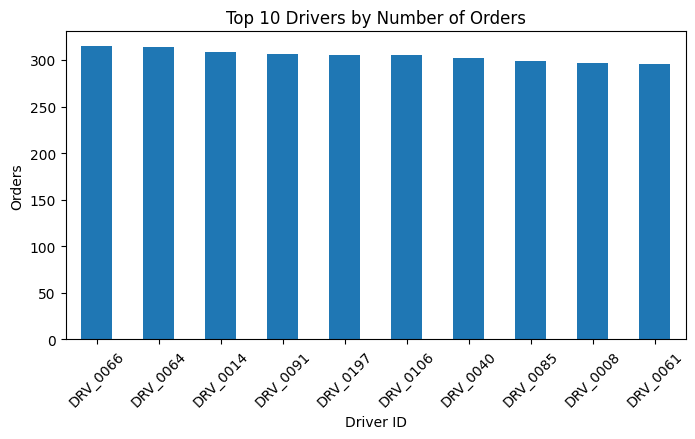

In [ ]:
#visualize
top_drivers.plot(kind="bar", figsize=(8, 4))

plt.title("Top 10 Drivers by Number of Orders")
plt.xlabel("Driver ID")
plt.ylabel("Orders")
plt.xticks(rotation=45)
plt.show()

In [ ]:
#Which driver groups have the Highest Delivery Times?
driver_exp.sort_values("avg_delivery_time",ascending=False).round(2)

,orders,avg_delivery_time,avg_delay
driver_experience_group,,,
7-12 Months,5101,35.33,4.28
13-24 Months,10266,35.32,4.21
25+ Months,27937,35.10,4.26
0-6 Months,5828,34.96,4.09


### Driver Analysis Findings

- The 0-6 months experience group has the lowest average delivery time.
- The 7-12 months experience group has the highest average delivery time.
- Driver rating shows no linear relationship with delivery time.
- Driver `DRC_0066` handled the highest number of orders.
- Driver experience shows minimal differences in delivery performance.

#**Traffic Analysis**

In [ ]:
# How does traffic affect delivery time?
# Which traffic condition has the highest delivery time?
# What percentage of orders occur under high traffic?
# Does high traffic increase delays?
# What is average ETA by traffic level?

traffic_analysis = completed.groupby("traffic_level").agg(
    orders=("order_id","count"),
    avg_delivery_time = ("actual_delivery_time_minutes","mean"),
    avg_eta= ("estimated_delivery_time_minutes","mean"),
    avg_delay=("delay_minutes","mean"),
    delay_rate=("is_delayed","mean")
)
traffic_analysis["delay_rate"] *=100
traffic_analysis.sort_values("avg_delivery_time",ascending=False).round(2)

,orders,avg_delivery_time,avg_eta,avg_delay,delay_rate
traffic_level,,,,,
High,14948,39.89,35.27,4.62,76.49
Medium,19197,35.02,30.81,4.21,76.20
Low,14987,30.59,26.72,3.88,74.97


In [ ]:
#traffic level having highest delivery time
traffic_analysis["avg_delivery_time"].idxmax()

'High'

In [ ]:
#percentage of orders under high traffic
df["traffic_level"].value_counts()

,count
traffic_level,
Medium,19522
High,15313
Low,15165


In [ ]:
high_traffic_pct = ((df["traffic_level"] == "High").mean() * 100)
print("High Traffic Orders:", round(high_traffic_pct, 2), "%")

High Traffic Orders: 30.63 %


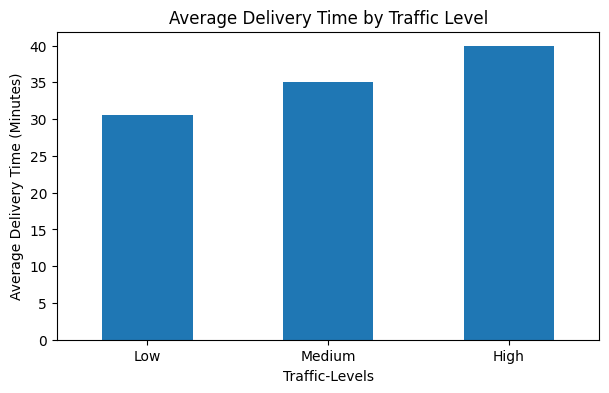

In [ ]:
#visualize
traffic_analysis["avg_delivery_time"].sort_values().plot(kind="bar",figsize=(7, 4))
plt.title("Average Delivery Time by Traffic Level")
plt.xlabel("Traffic-Levels")
plt.ylabel("Average Delivery Time (Minutes)")
plt.xticks(rotation=0)
plt.show()

### Traffic Analysis Findings

- High traffic has the highest average delivery time.
- Approximately 30.63% of orders occur under high traffic.
- Average delay is highest under high traffic.
- The delay rate is highest under high traffic.
- Average ETA generally increases as traffic conditions become heavier.

#**Weather Analysis**

In [ ]:
weather_analysis = completed.groupby("weather").agg(
    orders=("order_id", "count"),
    avg_delivery_time=("actual_delivery_time_minutes", "mean"),
    avg_eta=("estimated_delivery_time_minutes", "mean"),
    avg_delay=("delay_minutes", "mean"),
    delay_rate=("is_delayed", "mean")
)

weather_analysis["delay_rate"] *= 100
weather_analysis.round(2)

,orders,avg_delivery_time,avg_eta,avg_delay,delay_rate
weather,,,,,
Clear,27857,33.56,31.01,2.55,68.05
Cloudy,12581,35.12,30.83,4.29,80.38
Rain,7427,39.16,30.66,8.50,94.08
Storm,1267,47.07,31.42,15.65,98.11


In [ ]:
#Weather Associated With Longer Delivery
weather_analysis["avg_delivery_time"].idxmax()

'Storm'

In [ ]:
#Does Bad Weather Increase Delays?
weather_analysis[["avg_delay", "delay_rate"]].round(2)

,avg_delay,delay_rate
weather,,
Clear,2.55,68.05
Cloudy,4.29,80.38
Rain,8.50,94.08
Storm,15.65,98.11


*Difficult weather is associated with increased delivery delays*

In [ ]:
#Which Weather Has the Highest ETA?
weather_analysis["avg_eta"].idxmax()

'Storm'

In [ ]:
#Percentage of Orders Under Difficult Weather
df["weather"].value_counts()

,count
weather,
Clear,28248
Cloudy,12810
Rain,7627
Storm,1315


In [ ]:
difficult_weather= ["Rain","Storm"]
difficult_weather_pct = (df["weather"].isin(difficult_weather).mean() * 100)
print(
    "Orders in Difficult Weather:",
    round(difficult_weather_pct, 2),
    "%"
)

Orders in Difficult Weather: 17.88 %


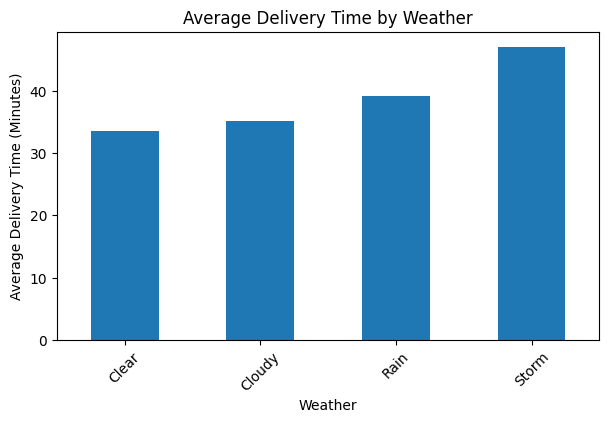

In [ ]:
#weather chart
weather_analysis["avg_delivery_time"].sort_values().plot(kind="bar",figsize=(7, 4))
plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather")
plt.ylabel("Average Delivery Time (Minutes)")
plt.xticks(rotation=45)
plt.show()

### Weather Analysis Findings

- 'Storm' weather has the highest average delivery time.
- 'Storm' weather has the highest average ETA.
- Delivery delays are highest under 'storm' weather.
- Approximately 17.88% of orders occur under difficult weather conditions.

#**Financial Analysis**

In [ ]:
# BUSINESS QUESTIONS :

# Total revenue/order value
# Average order value
# Total discount
# Total tax
# Total delivery fees
# Customer type with highest order value
# Restaurant category with highest revenue/order value
# Discount level vs order value

In [ ]:
#Main financial KPIs
financial_kpi = pd.DataFrame({
    "metric" : [
        "Total Order Value",
        "Average Order Value",
        "Total Discount",
        "Total Tax",
        "Total Delivery Fees"
    ],
    "value" : [
        df["order_total"].sum(),
        df["order_total"].mean(),
        df["discount_amount"].sum(),
        df["tax_amount"].sum(),
        df["delivery_fee"].sum()
    ]
})

financial_kpi.round(2)


,metric,value
0,Total Order Value,1908475.05
1,Average Order Value,38.17
2,Total Discount,70346.10
3,Total Tax,206439.79
4,Total Delivery Fees,153755.40


In [ ]:
#Which Customer Type Has the Highest Order Value?
customer_value = (
    df.groupby("customer_type")["order_total"]
      .sum()
      .sort_values(ascending=False)
)

customer_value.round(2)


,order_total
customer_type,
Regular,994353.11
Premium,500207.91
New,413914.03


In [ ]:
#Which Restaurant Category Generates the Highest Order Value?
category_value = (
    df.groupby("restaurant_primary_category")["order_total"]
      .sum()
      .sort_values(ascending=False)
)

category_value.head(10).round(2)

,order_total
restaurant_primary_category,
Burger,548857.93
Local,475661.65
Dessert,372612.28
Asian,176333.78
Pizza,168860.51
Healthy,166148.90


In [ ]:
#How Does Discount Level Affect Order Value?
discount_analysis = df.groupby(
    "discount_group", observed=True
).agg(
    orders=("order_id", "count"),
    avg_order_value=("order_total", "mean"),
    total_order_value=("order_total", "sum")
).round(2)

discount_analysis

,orders,avg_order_value,total_order_value
discount_group,,,
0-5%,36028,39.38,1418923.31
5-10%,5921,36.41,215596.21
10-20%,8051,34.03,273955.53


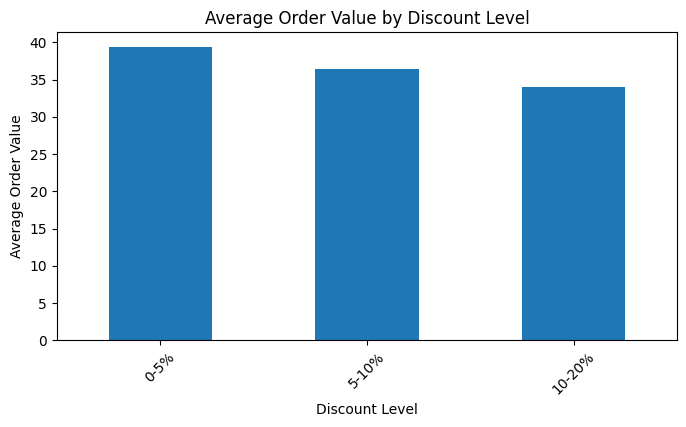

In [ ]:
#Financial Chart
discount_analysis["avg_order_value"].plot(kind="bar",figsize=(8, 4))
plt.title("Average Order Value by Discount Level")
plt.xlabel("Discount Level")
plt.ylabel("Average Order Value")
plt.xticks(rotation=45)
plt.show()

### Financial Analysis Findings

- Total order value is 1908475.05
- Average order value is 38.17
- Total discount provided is 70346.10
- Total tax collected is 206439.79
- Total delivery fees amount to 153755.40
- Regular customer type contributes the highest total order value.
- Burger restaurant category generates the highest total order value.
- Orders with 0-5% discount levels have the highest average order value.

#**ETA & Delay Analysis**

In [ ]:
#What is the Average ETA?
avg_eta= completed["estimated_delivery_time_minutes"].mean()
print("Average ETA:", round(avg_eta,2),"minutes")

Average ETA: 30.92 minutes


In [ ]:
#Which Factors Have the Strongest Relationship With Delivery Time?
eta_corr = completed[[
    "restaurant_preparation_time_minutes",
    "delivery_partner_experience_months",
    "delivery_partner_rating",
    "distance_km",
    "items_count",
    "order_hour",
    "actual_delivery_time_minutes"
]].corr()["actual_delivery_time_minutes"]

eta_corr.sort_values(ascending=False).round(2)

#closer to +1 → stronger positive relationship
#closer to -1 → stronger negative relationship
#closer to  0 → weak linear relationship

,actual_delivery_time_minutes
actual_delivery_time_minutes,1.00
distance_km,0.77
restaurant_preparation_time_minutes,0.50
items_count,0.38
order_hour,0.06
delivery_partner_rating,0.00
delivery_partner_experience_months,-0.00


In [ ]:
#Which Traffic Condition Has the Most Delays?
traffic_analysis[["avg_delay", "delay_rate"]
].sort_values("avg_delay",ascending=False).round(2)

,avg_delay,delay_rate
traffic_level,,
High,4.62,76.49
Medium,4.21,76.20
Low,3.88,74.97


In [ ]:
#Which Weather Condition Has the Most Delays?
weather_analysis[["avg_delay", "delay_rate"]
].sort_values("avg_delay",ascending=False).round(2)

,avg_delay,delay_rate
weather,,
Storm,15.65,98.11
Rain,8.50,94.08
Cloudy,4.29,80.38
Clear,2.55,68.05


In [ ]:
#Restaurant Preparation Time vs ETA
prep_eta_corr = completed["restaurant_preparation_time_minutes"
].corr(completed["estimated_delivery_time_minutes"])

print("Preparation Time vs ETA:",round(prep_eta_corr, 2))

#relationship is moderate positive

Preparation Time vs ETA: 0.45


In [ ]:
#Driver Experience vs ETA
completed.groupby("driver_experience_group",observed=True
)["estimated_delivery_time_minutes"].mean().round(2)

#from this we can conclude, experience does not significantly affect ETA

,estimated_delivery_time_minutes
driver_experience_group,
0-6 Months,30.87
7-12 Months,31.05
13-24 Months,31.11
25+ Months,30.84


In [ ]:
#Are There Unusually High Delivery Times?
Q1 = completed["actual_delivery_time_minutes"].quantile(0.25)
Q3 = completed["actual_delivery_time_minutes"].quantile(0.75)

IQR = Q3 - Q1

upper_limit = Q3 + 1.5 * IQR

In [ ]:
high_delivery_outliers = completed[completed["actual_delivery_time_minutes"]> upper_limit]

print("Upper Limit:", round(upper_limit, 2))
print("High Delivery Outliers:", len(high_delivery_outliers))

Upper Limit: 67.5
High Delivery Outliers: 1657


In [ ]:
high_delivery_outliers[[
    "order_id",
    "actual_delivery_time_minutes",
    "estimated_delivery_time_minutes",
    "delay_minutes",
    "traffic_level",
    "weather",
    "distance_km"
]].sort_values("actual_delivery_time_minutes",ascending=False).head(10)

,order_id,actual_delivery_time_minutes,estimated_delivery_time_minutes,delay_minutes,traffic_level,weather,distance_km
4961,ORD_004962,172.0,97,75.0,High,Storm,19.7
19908,ORD_019909,158.0,96,62.0,High,Storm,17.3
35011,ORD_035012,156.0,88,68.0,High,Storm,16.9
45243,ORD_045244,153.0,98,55.0,Medium,Storm,18.5
42251,ORD_042252,147.0,109,38.0,High,Rain,19.0
30294,ORD_030295,144.0,81,63.0,Medium,Storm,20.0
33399,ORD_033400,143.0,79,64.0,High,Storm,15.9
26474,ORD_026475,143.0,110,33.0,High,Rain,20.0
10776,ORD_010777,143.0,107,36.0,High,Rain,20.0
26259,ORD_026260,140.0,104,36.0,High,Rain,20.0


**The highest delivery-time outliers are mainly associated with longer delivery distances, adverse weather conditions such as storms and rain, and medium-to-high traffic levels. The most extreme order took 172 minutes compared with an estimated 97 minutes, resulting in a 75-minute delay. This suggests that a combination of distance, traffic, and weather conditions may contribute to unusually long delivery times.**

In [ ]:
#Factors that should be considered for future ETA prediction

'''eta_features = [
    "restaurant_preparation_time_minutes",
    "restaurant_primary_category",
    "restaurant_rating",
    "delivery_partner_experience_months",
    "delivery_partner_rating",
    "traffic_level",
    "weather",
    "distance_km",
    "items_count",
    "order_hour",
    "is_weekend"
    ]
  '''

### ETA & Delay Analysis Findings

- The average estimated delivery time is approximately 30.92 minutes.
- Apart from itself, `distance_km` shows one of the strongest numerical relationships with actual delivery time.
- High traffic is associated with the highest average delay.
- Storm weather is associated with the highest average delay.
- Restaurant preparation time has a moderate positive relationship with ETA.
- Driver experience has a minimal/no linear relationship with ETA.
- The IQR method identified 1657 unusually high delivery-time records.
- Important candidate factors for future ETA prediction include restaurant
  preparation time, driver characteristics, traffic, weather, distance,
  order characteristics and time-related variables.

#**Outlier Analysis**

In [ ]:
def count_outliers(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    return ((data[column] < lower) |
            (data[column] > upper)).sum()

In [ ]:
outlier_columns = [
    "order_total",
    "restaurant_preparation_time_minutes",
    "estimated_delivery_time_minutes",
    "actual_delivery_time_minutes",
    "discount_percent",
    "delivery_fee",
    "customer_age"
]

for col in outlier_columns:
    print(
        col,
        ":",
        count_outliers(completed, col)
    )

order_total : 2552
restaurant_preparation_time_minutes : 1429
estimated_delivery_time_minutes : 1714
actual_delivery_time_minutes : 1657
discount_percent : 0
delivery_fee : 85
customer_age : 13


### Outlier Treatment

Potential outliers were identified using the IQR method. Outliers were
not automatically removed because extreme values may represent genuine
delivery or business conditions. They were retained for further analysis
unless proven to be data-entry errors.

#**Correlation / Relationship Analysis**

In [ ]:
corr_columns = [
    "restaurant_preparation_time_minutes",
    "delivery_partner_experience_months",
    "delivery_partner_rating",
    "distance_km",
    "items_count",
    "estimated_delivery_time_minutes",
    "actual_delivery_time_minutes",
    "delay_minutes"
]

correlation = completed[corr_columns].corr().round(2)

correlation

,restaurant_preparation_time_minutes,delivery_partner_experience_months,delivery_partner_rating,distance_km,items_count,estimated_delivery_time_minutes,actual_delivery_time_minutes,delay_minutes
restaurant_preparation_time_minutes,1.00,0.00,-0.00,0.00,0.74,0.45,0.50,0.29
delivery_partner_experience_months,0.00,1.00,0.05,-0.01,0.00,-0.00,-0.00,0.01
delivery_partner_rating,-0.00,0.05,1.00,0.01,-0.00,0.00,0.00,-0.00
distance_km,0.00,-0.01,0.01,1.00,0.01,0.81,0.77,0.18
items_count,0.74,0.00,-0.00,0.01,1.00,0.43,0.38,-0.01
estimated_delivery_time_minutes,0.45,-0.00,0.00,0.81,0.43,1.00,0.93,0.16
actual_delivery_time_minutes,0.50,-0.00,0.00,0.77,0.38,0.93,1.00,0.51
delay_minutes,0.29,0.01,-0.00,0.18,-0.01,0.16,0.51,1.00


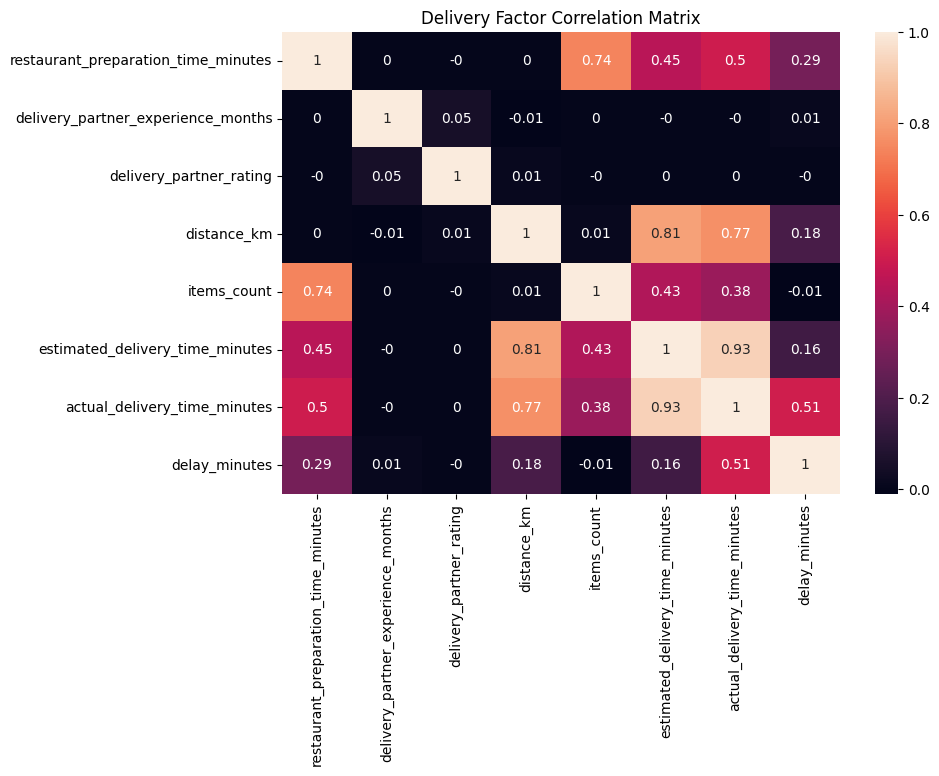

In [ ]:
plt.figure(figsize=(9, 6))
sns.heatmap(
    correlation,
    annot=True
)

plt.title("Delivery Factor Correlation Matrix")
plt.show()

In [ ]:
df.to_csv("food_delivery_cleaned.csv", index=False)

In [ ]:
print("Cleaned dataset exported successfully!")
print("Final Shape:", df.shape)

Cleaned dataset exported successfully!
Final Shape: (50000, 47)


In [ ]:
print(df.columns.tolist())

['order_id', 'customer_id', 'restaurant_id', 'driver_id', 'order_timestamp', 'order_date', 'order_hour', 'day_of_week', 'is_weekend', 'city', 'delivery_area', 'customer_age', 'customer_type', 'restaurant_type', 'restaurant_primary_category', 'restaurant_rating', 'items_count', 'subtotal', 'discount_percent', 'tax_amount', 'service_fee', 'delivery_fee', 'order_total', 'payment_method', 'tip_amount', 'distance_km', 'weather', 'traffic_level', 'delivery_partner_experience_months', 'delivery_partner_rating', 'restaurant_preparation_time_minutes', 'estimated_delivery_time_minutes', 'actual_delivery_time_minutes', 'late_delivery', 'order_status', 'cancellation_reason', 'customer_rating', 'discount_amount', 'delay_minutes', 'is_delayed', 'age_group', 'day_type', 'time_of_day', 'distance_category', 'driver_experience_group', 'discount_group', 'prep_time_group']


In [ ]:
cleaned_df = pd.read_csv("food_delivery_cleaned.csv")

print(cleaned_df.shape)
cleaned_df.head()

(50000, 47)


,order_id,customer_id,restaurant_id,driver_id,order_timestamp,order_date,order_hour,day_of_week,is_weekend,city,...,discount_amount,delay_minutes,is_delayed,age_group,day_type,time_of_day,distance_category,driver_experience_group,discount_group,prep_time_group
0,ORD_000001,CUS_00001,RES_0008,DRV_0075,2025-10-05 15:54:00,2025-10-05,15,Sunday,1,City_C,...,0.000,4.0,1.0,35-44,Weekend,Afternoon,Short,13-24 Months,0-5%,21-30 min
1,ORD_000002,CUS_00013,RES_0024,DRV_0131,2025-10-01 20:00:00,2025-10-01,20,Wednesday,0,City_A,...,0.000,4.0,1.0,18-24,Weekday,Evening,Short,25+ Months,0-5%,11-20 min
2,ORD_000003,CUS_00049,RES_0013,DRV_0087,2025-10-07 18:24:00,2025-10-07,18,Tuesday,0,City_C,...,1.012,9.0,1.0,25-34,Weekday,Evening,Very Long,0-6 Months,5-10%,11-20 min
3,ORD_000004,CUS_00007,RES_0001,DRV_0177,2025-10-30 16:54:00,2025-10-30,16,Thursday,0,City_A,...,0.886,8.0,1.0,18-24,Weekday,Afternoon,Medium,25+ Months,5-10%,11-20 min
4,ORD_000005,CUS_00325,RES_0029,DRV_0114,2025-10-15 18:34:00,2025-10-15,18,Wednesday,0,City_B,...,3.016,10.0,1.0,18-24,Weekday,Evening,Long,13-24 Months,10-20%,0-10 min


In [ ]:
from google.colab import files

files.download("food_delivery_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.to_csv(
    "/content/drive/MyDrive/food_delivery_cleaned.csv",
    index=False
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv(
    "/content/drive/MyDrive/food_delivery_cleaned.csv"
)

print(df.shape)

(50000, 47)


In [ ]:
print("Missing tips:", df["tip_amount"].isna().sum())

df.iloc[12285:12295][
    ["order_id", "order_status", "tip_amount"]
]

Missing tips: 868


,order_id,order_status,tip_amount
12285,ORD_012286,Completed,0.00
12286,ORD_012287,Completed,3.49
12287,ORD_012288,Completed,1.10
12288,ORD_012289,Completed,0.00
12289,ORD_012290,Completed,0.00
12290,ORD_012291,Completed,0.00
12291,ORD_012292,Completed,3.01
12292,ORD_012293,Completed,2.62
12293,ORD_012294,Completed,0.00
12294,ORD_012295,Completed,0.00


In [ ]:
pd.to_numeric(
    df["tip_amount"], errors="coerce"
).isna().sum()

np.int64(868)

In [ ]:
pd.crosstab(
    df["order_status"],
    df["tip_amount"].isna()
)

tip_amount,False,True
order_status,,
Cancelled,0,868
Completed,49132,0


In [ ]:
invalid_tips = (
    pd.to_numeric(df["tip_amount"], errors="coerce").isna()
    & df["tip_amount"].notna()
)

print("Invalid tip values:", invalid_tips.sum())

Invalid tip values: 0


In [ ]:
df.iloc[12289:12293].T

,12289,12290,12291,12292
order_id,ORD_012290,ORD_012291,ORD_012292,ORD_012293
customer_id,CUS_00004,CUS_00148,CUS_00001,CUS_00060
restaurant_id,RES_0005,RES_0001,RES_0003,RES_0205
driver_id,DRV_0121,DRV_0030,DRV_0083,DRV_0115
order_timestamp,2025-10-27 07:48:00,2025-10-02 19:53:00,2025-10-20 08:37:00,2025-10-02 22:17:00
order_date,2025-10-27,2025-10-02,2025-10-20,2025-10-02
order_hour,7,19,8,22
day_of_week,Monday,Thursday,Monday,Thursday
is_weekend,0,0,0,0
city,City_A,City_A,City_C,City_B


In [ ]:
df.isna().sum()[lambda x: x > 0]

,0
tip_amount,868
actual_delivery_time_minutes,868
late_delivery,868
cancellation_reason,49132
customer_rating,868
delay_minutes,868
is_delayed,868


In [ ]:
df.to_csv(
    "/content/drive/MyDrive/food_delivery_mysql.csv",
    index=False,
    na_rep="\\N"
)